### **Author:** Giuseppe Muschetta — Data Scientist (M.Sc. Data Science & Business Informatics, University of Pisa)
#### **Project:** SoundPulse — End-to-End ML on Spotify
#### **Notebook:** 5_regression.ipynb
#### **Purpose:** Popularity Regression with Ridge, Linear SVR, RF, XGB, GBR; uniform CV, parity/residual diagnostics, permutation importance.

In [28]:
from __future__ import annotations

import matplotlib.pyplot as plt
import seaborn as sns
import multiprocessing
import os, sys, time, ast
import math
import pandas as pd
import numpy as np


import warnings
warnings.filterwarnings('ignore')

# --- IMPOSTAZIONI GLOBALI PER I GRAFICI ---
# Stile base
plt.style.use("dark_background")
sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette="icefire",
    font="sans-serif",
    font_scale=1.1
)

# Aggiornamenti avanzati
plt.rcParams.update({
    # Colori e sfondi
    'figure.facecolor': '#111111',
    'axes.facecolor': '#111111',
    'savefig.facecolor': '#111111',
    'axes.edgecolor': 'white',
    'axes.labelcolor': 'white',
    'axes.titlecolor': 'white',
    'text.color': 'white',
    'xtick.color': 'lightgray',
    'ytick.color': 'lightgray',

    # Font e peso
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold',

    # Griglia elegante
    'axes.grid': True,
    'grid.color': 'gray',
    'grid.linestyle': '--',
    'grid.linewidth': 0.4,
    'grid.alpha': 0.3,  # meno invasiva

    # Tick leggeri
    'xtick.direction': 'out',
    'ytick.direction': 'out',

    # Leggibilità generale
    'legend.edgecolor': 'gray',
    'legend.facecolor': '#222222',
    'legend.fontsize': 'medium',
})

print("✅ Impostazioni grafiche caricate.")

# --- CREAZIONE DIRECTORY PER I MODELLI ---
# print("--- Creazione directory per i modelli ---")
# models_dir = 'models_time_series_classification/'
# os.makedirs(models_dir, exist_ok=True)
# print(f"✅ Directory per i modelli '{models_dir}' pronta.")

# --- CREAZIONE DIRECTORY PER I PLOT ---
plots_dir = 'plots_regression/'
os.makedirs(plots_dir, exist_ok=True)
print(f"✅ Directory per i grafici '{plots_dir}' pronta.")

# --- CARICAMENTO DEL DATASET PREPARATO ---
dataset_dir = "Dataset/"
dataset_name = "spotify_cleaned.csv"
try:
    df = pd.read_csv(os.path.join(dataset_dir, dataset_name))
    print(f"✅ Dataset preparato caricato: {df.shape[0]} righe, {df.shape[1]} colonne.")
except FileNotFoundError as e:
    print(f"❌ Errore: File non trovato. Assicurati di aver eseguito il Modulo 0 e salvato '{dataset_name}'.")
    sys.exit(1)


✅ Impostazioni grafiche caricate.
✅ Directory per i grafici 'plots_regression/' pronta.
✅ Dataset preparato caricato: 108299 righe, 66 colonne.


### LINEAR REGRESSION on "popularity" variable

#### Linear Regression with Ridge Regressor (aka Tikhonov regularization)

In [2]:
columns_to_use = []
for col in df.columns:
    if col.startswith("std_"):
        if col != "std_popularity":
            columns_to_use.append(col)
# end_for
print(columns_to_use)

X = df[columns_to_use].copy()
y = df["std_popularity"].copy()

from sklearn.model_selection import train_test_split, RepeatedKFold

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

['std_explicit', 'std_danceability', 'std_energy', 'std_loudness', 'std_speechiness', 'std_acousticness', 'std_instrumentalness', 'std_liveness', 'std_valence', 'std_tempo', 'std_time_signature', 'std_duration_mins']


=== Ridge Regression ===
MSE            : 0.9498
RMSE           : 0.9746
MAE            : 0.8089
R² Score       : 0.0292


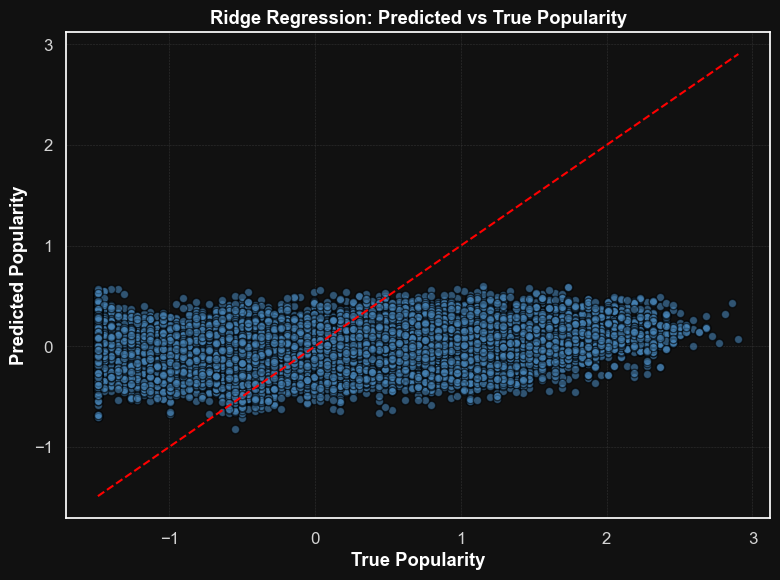

In [8]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Il problema di regressione lineare è il seguente:
# ||y - Xw||^2_2 + alpha * ||w||^2_2
ridge = Ridge(
    alpha=1,
    max_iter=10000,
    tol=1e-5,
    random_state=42
)
ridge.fit(X_train, y_train)

# Predizioni
y_pred = ridge.predict(X_test)

# Metriche
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Stampa metriche
print("=== Ridge Regression ===")
print(f"MSE            : {mse:.4f}")
print(f"RMSE           : {rmse:.4f}")
print(f"MAE            : {mae:.4f}")
print(f"R² Score       : {r2:.4f}")

# Plot Predicted vs True
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='steelblue', edgecolors='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("True Popularity")
plt.ylabel("Predicted Popularity")
plt.title("Ridge Regression: Predicted vs True Popularity")
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "ridge_pred_vs_true.png"), dpi=300, bbox_inches='tight')
plt.show()


### Linear SVR

=== SVR Lineare ===
MSE            : 0.9648
RMSE           : 0.9822
MAE            : 0.8017
R² Score       : 0.0139


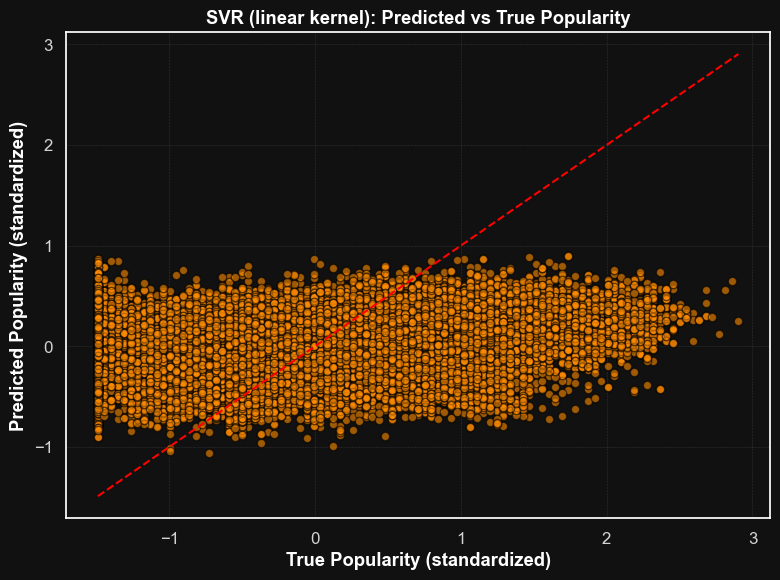

In [10]:
from sklearn.svm import LinearSVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# SVR con kernel lineare
linear_svr = LinearSVR(
    epsilon=0.1,
    C=1.0,
    tol=1e-5,
    max_iter=10000,
    random_state=42
)
linear_svr.fit(X_train, y_train)

# Predizioni
y_pred = linear_svr.predict(X_test)

# Metriche
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Stampa
print("=== SVR Lineare ===")
print(f"MSE            : {mse:.4f}")
print(f"RMSE           : {rmse:.4f}")
print(f"MAE            : {mae:.4f}")
print(f"R² Score       : {r2:.4f}")

# Plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='darkorange', edgecolors='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("True Popularity (standardized)")
plt.ylabel("Predicted Popularity (standardized)")
plt.title("SVR (linear kernel): Predicted vs True Popularity")
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "svr_linear_pred_vs_true.png"), dpi=300, bbox_inches='tight')
plt.show()


## NON LINEAR REGRESSION

### Regression with RandomForestRegressor

In [29]:
import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from joblib import dump
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, RepeatedKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance


# --- modello base ---
rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1,
    oob_score=True,      # stima out-of-bag per generalizzazione
    bootstrap=True
)

# --- griglia iperparametri ---
param_grid = {
    "n_estimators": [800],
    "max_depth": [None],
    "min_samples_split": [2],
    "min_samples_leaf": [1],
    "max_features": ["sqrt"] # ["sqrt", "log2", 0.5, 0.7],
}

# --- cross-validation robusta ---
cv = RepeatedKFold(n_splits=5, n_repeats=2, random_state=42)

# --- scoring multi-metrico (refit su R2 per confronto con altri modelli) ---
scoring = {
    "r2": "r2",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
}

grid_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring=scoring,
    refit="r2",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

# --- training ---
t0 = time.time()
grid_rf.fit(X_train, y_train)
fit_time = time.time() - t0

best_rf = grid_rf.best_estimator_
best_params = grid_rf.best_params_

# --- valutazione ---
y_pred = best_rf.predict(X_test)

def regression_report(y_true, y_hat, prefix="Test"):
    mse = mean_squared_error(y_true, y_hat)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_hat)
    r2 = r2_score(y_true, y_hat)
    return {"prefix": prefix, "MSE": mse, "RMSE": rmse, "MAE": mae, "R2": r2}

metrics_test = regression_report(y_test, y_pred, "Test")
metrics_train = regression_report(y_train, best_rf.predict(X_train), "Train")

print("=== Random Forest Regressor ===")
print(f"Best Params      : {best_params}")
print(f"CV best R2       : {grid_rf.best_score_:.4f} (refit='r2') | Fit time: {fit_time:.1f}s")
for d in (metrics_train, metrics_test):
    print(f"{d['prefix']:<5} -> MSE: {d['MSE']:.4f} | RMSE: {d['RMSE']:.4f} | MAE: {d['MAE']:.4f} | R2: {d['R2']:.4f}")



Fitting 10 folds for each of 1 candidates, totalling 10 fits
=== Random Forest Regressor ===
Best Params      : {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 800}
CV best R2       : 0.4920 (refit='r2') | Fit time: 65.9s
Train -> MSE: 0.0871 | RMSE: 0.2951 | MAE: 0.1922 | R2: 0.9106
Test  -> MSE: 0.4608 | RMSE: 0.6788 | MAE: 0.4877 | R2: 0.5291


#### RandomForestRegressor Visualization

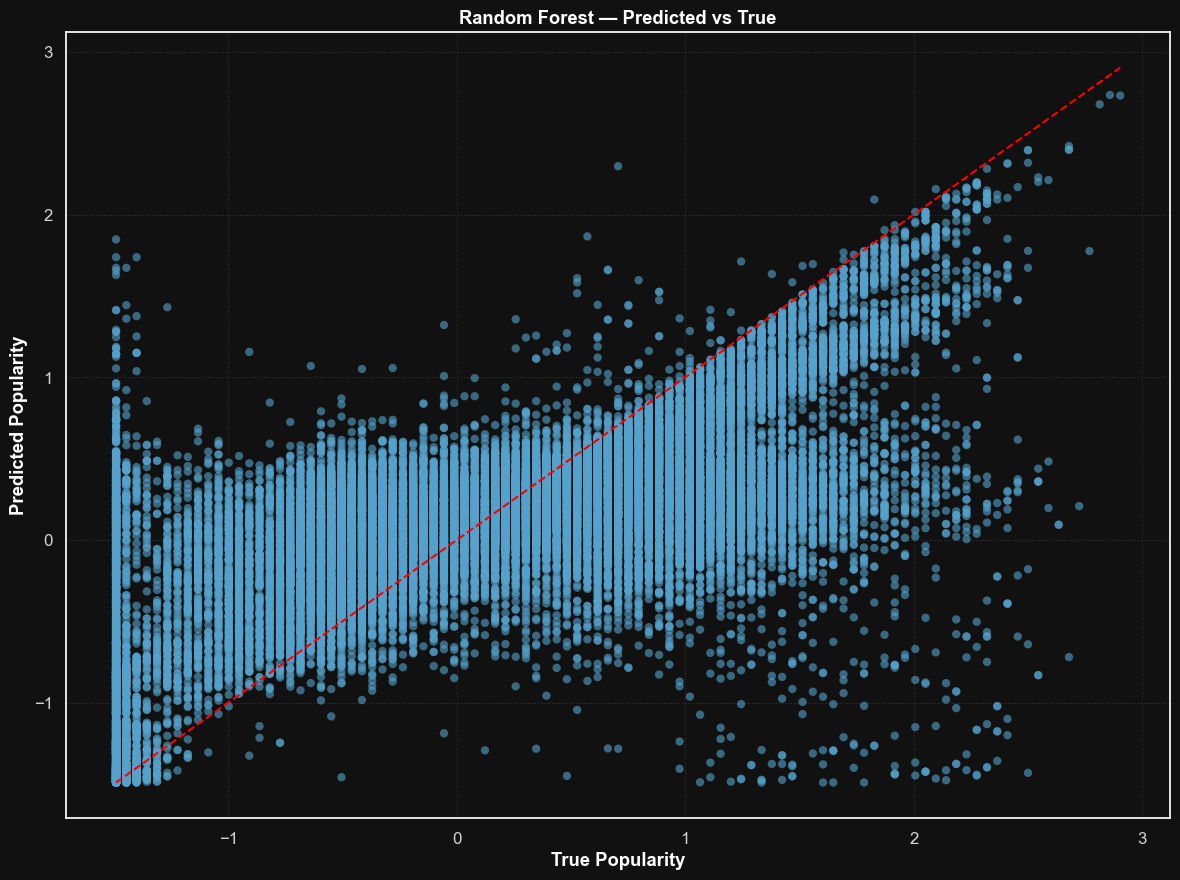

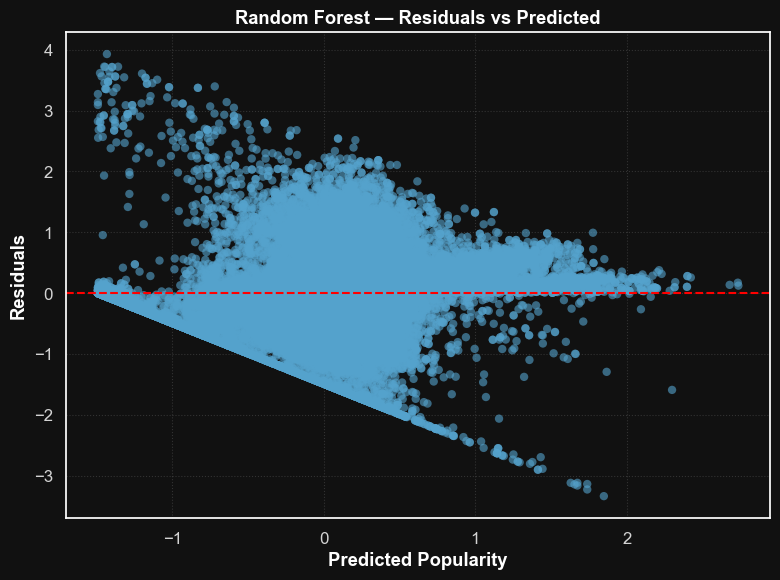

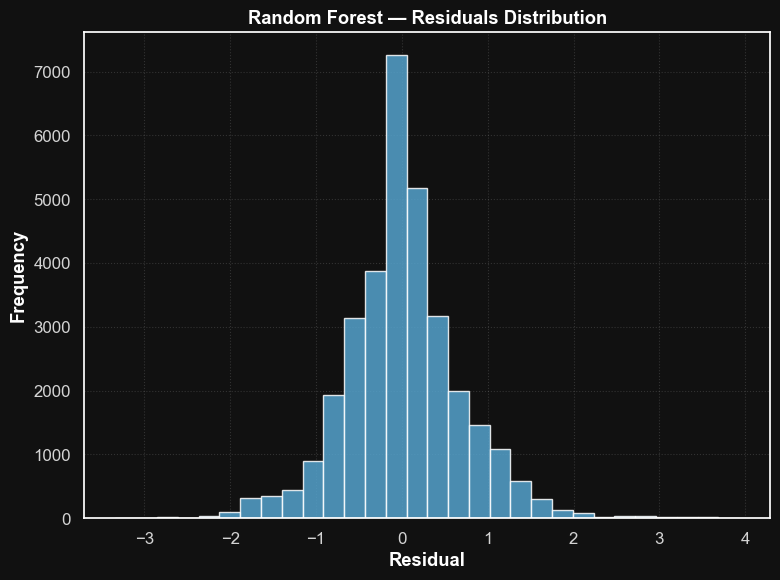

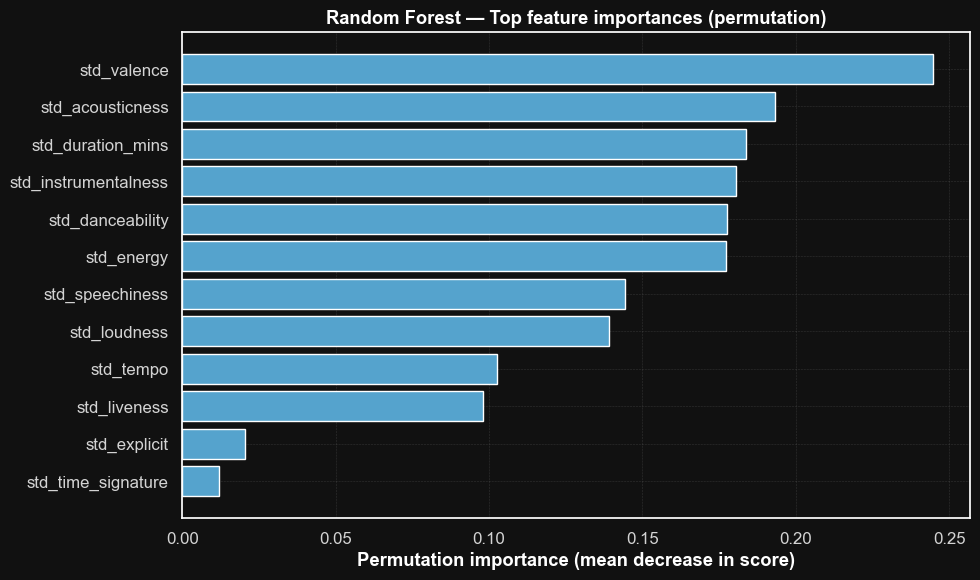

OOB R2           : 0.5314


In [30]:
# --- parity plot (Predicted vs True) ---
plt.figure(figsize=(12, 9))
plt.scatter(y_test, y_pred, alpha=0.6, edgecolors="none")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, linestyle="--", color="red")
plt.xlabel("True Popularity")
plt.ylabel("Predicted Popularity")
plt.title("Random Forest — Predicted vs True")
plt.grid(True, linestyle=":", linewidth=0.8)
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "rf_pred_vs_true.png"), dpi=300, bbox_inches="tight")
plt.show()

# --- analisi residui ---
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.6, edgecolors="none")
plt.axhline(0, linestyle="--", color="red")
plt.xlabel("Predicted Popularity")
plt.ylabel("Residuals")
plt.title("Random Forest — Residuals vs Predicted")
plt.grid(True, linestyle=":", linewidth=0.8)
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "rf_residuals_vs_pred.png"), dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 6))
plt.hist(residuals, bins=30, alpha=0.85)
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Random Forest — Residuals Distribution")
plt.grid(True, linestyle=":", linewidth=0.8)
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "rf_residuals_hist.png"), dpi=300, bbox_inches="tight")
plt.show()

# --- importanza permutata (su test) ---
perm = permutation_importance(
    best_rf, X_test, y_test,
    n_repeats=10, random_state=42, n_jobs=-1
)

importances = pd.DataFrame({
    "feature": X_test.columns if hasattr(X_test, "columns") else [f"f{i}" for i in range(X_test.shape[1])],
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)


topk = min(20, importances.shape[0])
plt.figure(figsize=(10, 6))
plt.barh(importances["feature"].head(topk)[::-1], importances["importance_mean"].head(topk)[::-1])
plt.xlabel("Permutation importance (mean decrease in score)")
plt.title("Random Forest — Top feature importances (permutation)")
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "rf_perm_importance_topk.png"), dpi=300, bbox_inches="tight")
plt.show()

# --- OOB score se disponibile ---
if hasattr(best_rf, "oob_score_"):
    print(f"OOB R2           : {best_rf.oob_score_:.4f}")


#### XGBoost Regressor

In [31]:
# %%
import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from joblib import dump
from sklearn.model_selection import GridSearchCV, RepeatedKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor


# --- modello base ---
xgb = XGBRegressor(
    random_state=42,
    n_estimators=800,
    learning_rate=0.1,
    subsample=1.0,
    colsample_bytree=1.0,
    min_child_weight=1,
    reg_alpha=0.0,
    reg_lambda=1.0,
    objective="reg:squarederror",
    tree_method="hist",   # più veloce su CPU
    n_jobs=-1,
    verbosity=2
)


param_grid = {
    "n_estimators": [300, 500],
    "max_depth": [15, 18],
}

# --- cross-validation robusta ---
cv = RepeatedKFold(n_splits=5, n_repeats=2, random_state=42)

# --- scoring multi-metrico (refit su R2 per confronto con altri modelli) ---
scoring = {
    "r2": "r2",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
}

grid_xgb = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    scoring=scoring,
    refit="r2",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

# --- training ---
t0 = time.time()
grid_xgb.fit(X_train, y_train)
fit_time = time.time() - t0

best_xgb = grid_xgb.best_estimator_
best_params = grid_xgb.best_params_

# --- valutazione ---
y_pred = best_xgb.predict(X_test)

def regression_report(y_true, y_hat, prefix="Test"):
    mse = mean_squared_error(y_true, y_hat)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_hat)
    r2 = r2_score(y_true, y_hat)
    return {"prefix": prefix, "MSE": mse, "RMSE": rmse, "MAE": mae, "R2": r2}

metrics_test = regression_report(y_test, y_pred, "Test")
metrics_train = regression_report(y_train, best_xgb.predict(X_train), "Train")

print("=== XGBoost Regressor ===")
print(f"Best Params      : {best_params}")
print(f"CV best R2       : {grid_xgb.best_score_:.4f} (refit='r2') | Fit time: {fit_time:.1f}s")
for d in (metrics_train, metrics_test):
    print(f"{d['prefix']:<5} -> MSE: {d['MSE']:.4f} | RMSE: {d['RMSE']:.4f} | MAE: {d['MAE']:.4f} | R2: {d['R2']:.4f}")



Fitting 10 folds for each of 4 candidates, totalling 40 fits
[09:37:49] INFO: /Users/runner/work/xgboost/xgboost/src/data/iterative_dmatrix.cc:53: Finished constructing the `IterativeDMatrix`: (60647, 12, 727764).
[09:37:52] INFO: /Users/runner/work/xgboost/xgboost/src/data/iterative_dmatrix.cc:53: Finished constructing the `IterativeDMatrix`: (60647, 12, 727764).
[09:37:52] INFO: /Users/runner/work/xgboost/xgboost/src/data/iterative_dmatrix.cc:53: Finished constructing the `IterativeDMatrix`: (60647, 12, 727764).
[09:37:52] INFO: /Users/runner/work/xgboost/xgboost/src/data/iterative_dmatrix.cc:53: Finished constructing the `IterativeDMatrix`: (60647, 12, 727764).
[09:37:52] INFO: /Users/runner/work/xgboost/xgboost/src/data/iterative_dmatrix.cc:53: Finished constructing the `IterativeDMatrix`: (60648, 12, 727776).
[09:37:52] INFO: /Users/runner/work/xgboost/xgboost/src/data/iterative_dmatrix.cc:53: Finished constructing the `IterativeDMatrix`: (60647, 12, 727764).
[09:37:52] INFO: /Use

#### XGBoost Visualization

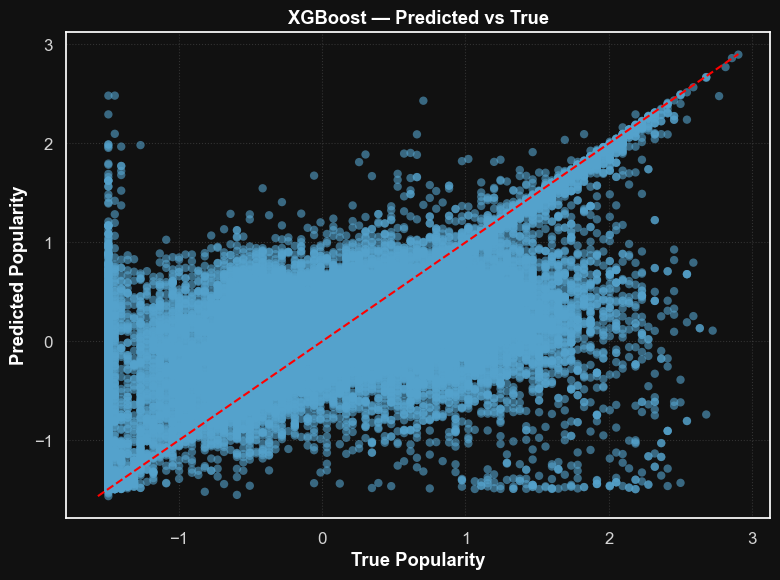

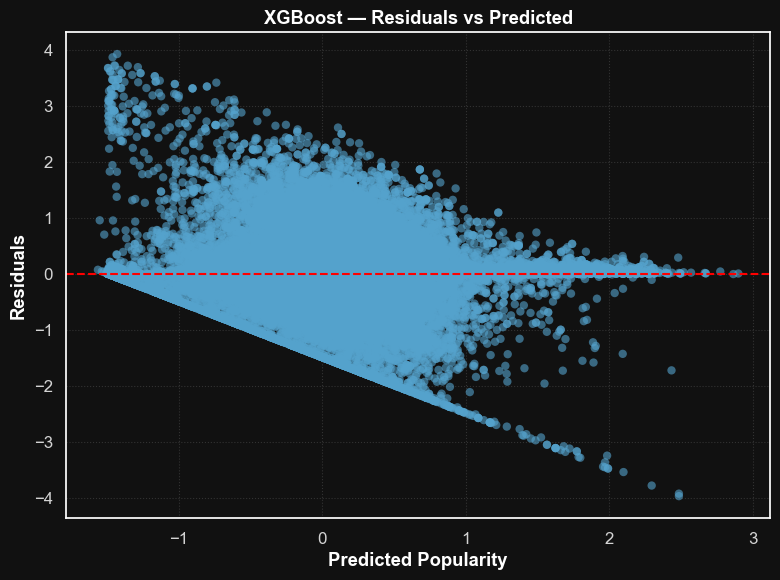

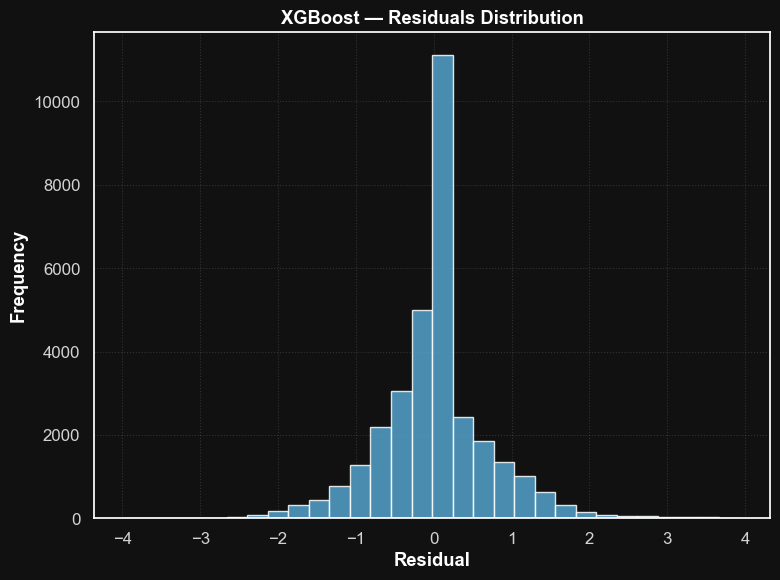

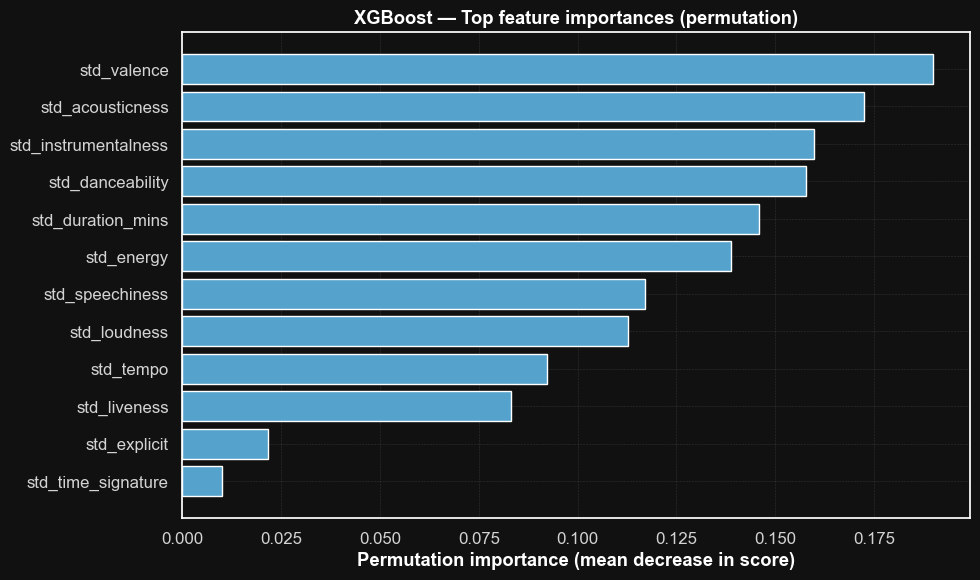

In [32]:
# --- parity plot (Predicted vs True) ---
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, edgecolors="none")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, linestyle="--", color="red")
plt.xlabel("True Popularity")
plt.ylabel("Predicted Popularity")
plt.title("XGBoost — Predicted vs True")
plt.grid(True, linestyle=":", linewidth=0.8)
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "xgb_pred_vs_true.png"), dpi=300, bbox_inches="tight")
plt.show()

# --- analisi residui ---
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.6, edgecolors="none")
plt.axhline(0, linestyle="--", color="red")
plt.xlabel("Predicted Popularity")
plt.ylabel("Residuals")
plt.title("XGBoost — Residuals vs Predicted")
plt.grid(True, linestyle=":", linewidth=0.8)
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "xgb_residuals_vs_pred.png"), dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 6))
plt.hist(residuals, bins=30, alpha=0.85)
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("XGBoost — Residuals Distribution")
plt.grid(True, linestyle=":", linewidth=0.8)
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "xgb_residuals_hist.png"), dpi=300, bbox_inches="tight")
plt.show()

# --- importanza permutata (su test) ---
perm = permutation_importance(
    best_xgb, X_test, y_test,
    n_repeats=10, random_state=42, n_jobs=-1
)

importances = pd.DataFrame({
    "feature": X_test.columns if hasattr(X_test, "columns") else [f"f{i}" for i in range(X_test.shape[1])],
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)


topk = min(20, importances.shape[0])
plt.figure(figsize=(10, 6))
plt.barh(importances["feature"].head(topk)[::-1], importances["importance_mean"].head(topk)[::-1])
plt.xlabel("Permutation importance (mean decrease in score)")
plt.title("XGBoost — Top feature importances (permutation)")
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "xgb_perm_importance_topk.png"), dpi=300, bbox_inches="tight")
plt.show()


#### GradientBoostingRegressor (sklearn version of XGBoost)

In [23]:
import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from joblib import dump
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, RepeatedKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance


# --- modello base ---
gbr = GradientBoostingRegressor(
    random_state=42,
    loss="squared_error",
    learning_rate=0.1,
    n_estimators=300,
    subsample=1.0,
    criterion="friedman_mse",
    min_samples_split=2,
    min_samples_leaf=1,
    max_depth=3,
    max_features=None,
    validation_fraction=0.1,
    n_iter_no_change=None,
    tol=1e-4,
    ccp_alpha=0.0
)

# --- griglia iperparametri (equilibrata) ---
param_grid = {
    "n_estimators": [300],
    "max_depth": [5, 7, 15, 20],
    "min_samples_split": [2, 3],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt"],
}

# --- cross-validation robusta ---
cv = RepeatedKFold(n_splits=5, n_repeats=2, random_state=42)

# --- scoring multi-metrico (refit su R2) ---
scoring = {
    "r2": "r2",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
}

grid_gbr = GridSearchCV(
    estimator=gbr,
    param_grid=param_grid,
    scoring=scoring,
    refit="r2",
    cv=cv,
    n_jobs=-1,
    verbose=2,
    return_train_score=True
)

# --- training ---
t0 = time.time()
grid_gbr.fit(X_train, y_train)
fit_time = time.time() - t0

best_gbr = grid_gbr.best_estimator_
best_params = grid_gbr.best_params_


# --- valutazione ---
y_pred = best_gbr.predict(X_test)

def regression_report(y_true, y_hat, prefix="Test"):
    mse = mean_squared_error(y_true, y_hat)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_hat)
    r2 = r2_score(y_true, y_hat)
    return {"prefix": prefix, "MSE": mse, "RMSE": rmse, "MAE": mae, "R2": r2}

metrics_test = regression_report(y_test, y_pred, "Test")
metrics_train = regression_report(y_train, best_gbr.predict(X_train), "Train")

print("=== Gradient Boosting Regressor ===")
print(f"Best Params      : {best_params}")
print(f"CV best R2       : {grid_gbr.best_score_:.4f} (refit='r2') | Fit time: {fit_time:.1f}s")
for d in (metrics_train, metrics_test):
    print(f"{d['prefix']:<5} -> MSE: {d['MSE']:.4f} | RMSE: {d['RMSE']:.4f} | MAE: {d['MAE']:.4f} | R2: {d['R2']:.4f}")



Fitting 10 folds for each of 16 candidates, totalling 160 fits
=== Gradient Boosting Regressor ===
Best Params      : {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}
CV best R2       : 0.4833 (refit='r2') | Fit time: 278.8s
Train -> MSE: 0.0319 | RMSE: 0.1787 | MAE: 0.0256 | R2: 0.9672
Test  -> MSE: 0.4677 | RMSE: 0.6839 | MAE: 0.4395 | R2: 0.5220


#### GradientBoostingRegressor Visualization

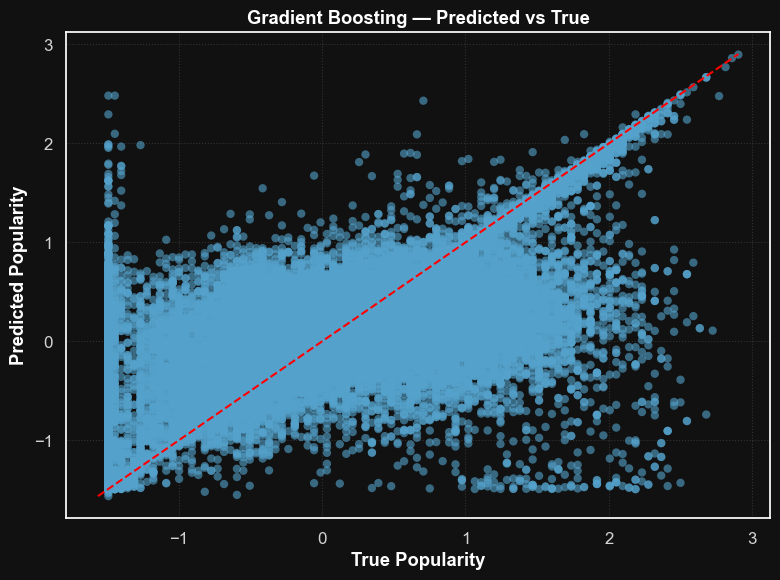

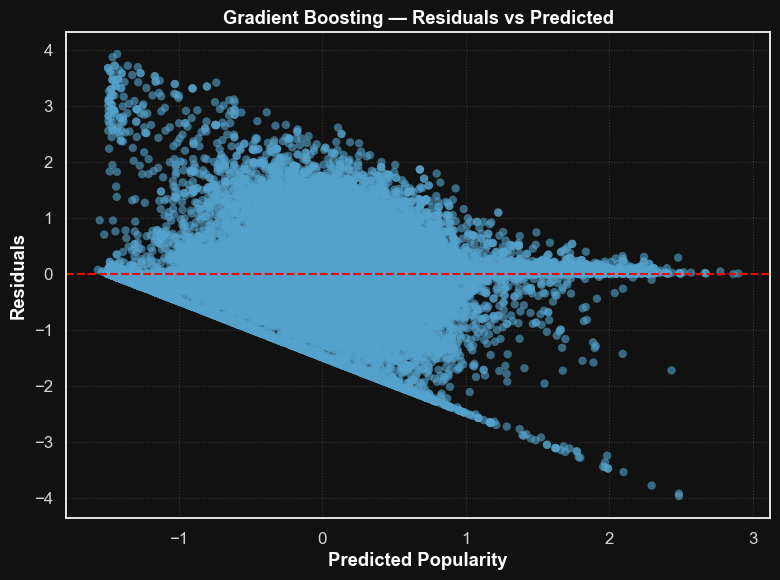

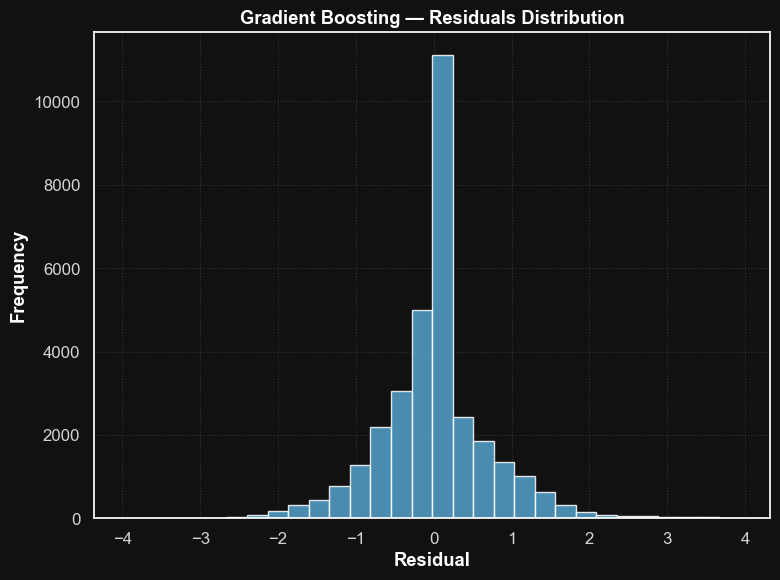

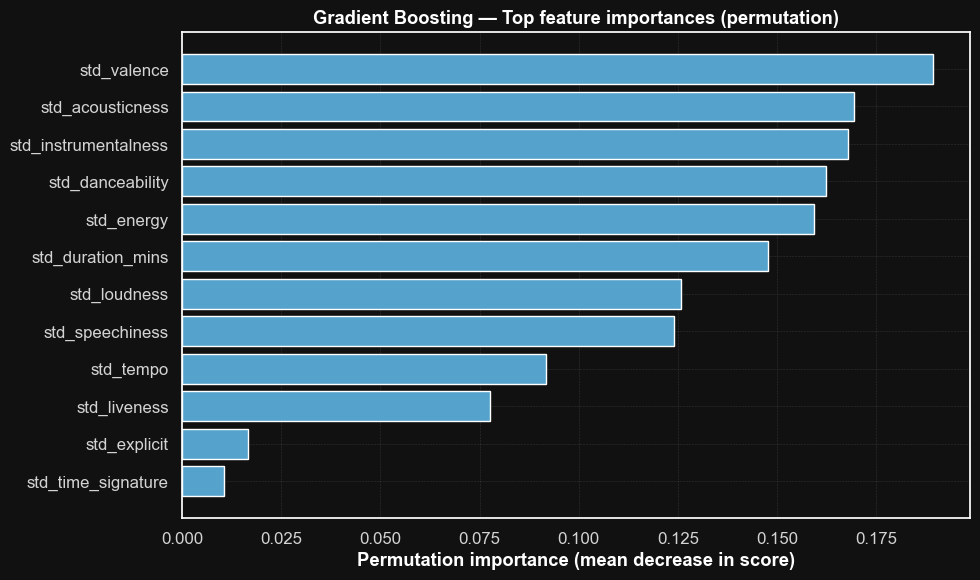

In [33]:
# --- parity plot (Predicted vs True) ---
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, edgecolors="none")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, linestyle="--", color="red")
plt.xlabel("True Popularity")
plt.ylabel("Predicted Popularity")
plt.title("Gradient Boosting — Predicted vs True")
plt.grid(True, linestyle=":", linewidth=0.8)
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "gbr_pred_vs_true.png"), dpi=300, bbox_inches="tight")
plt.show()

# --- analisi residui ---
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.6, edgecolors="none")
plt.axhline(0, linestyle="--", color="red")
plt.xlabel("Predicted Popularity")
plt.ylabel("Residuals")
plt.title("Gradient Boosting — Residuals vs Predicted")
plt.grid(True, linestyle=":", linewidth=0.8)
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "gbr_residuals_vs_pred.png"), dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 6))
plt.hist(residuals, bins=30, alpha=0.85)
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Gradient Boosting — Residuals Distribution")
plt.grid(True, linestyle=":", linewidth=0.8)
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "gbr_residuals_hist.png"), dpi=300, bbox_inches="tight")
plt.show()

# --- importanza permutata (su test) ---
perm = permutation_importance(
    best_gbr, X_test, y_test,
    n_repeats=10, random_state=42, n_jobs=-1
)

importances = pd.DataFrame({
    "feature": X_test.columns if hasattr(X_test, "columns") else [f"f{i}" for i in range(X_test.shape[1])],
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)


topk = min(20, importances.shape[0])
plt.figure(figsize=(10, 6))
plt.barh(importances["feature"].head(topk)[::-1], importances["importance_mean"].head(topk)[::-1])
plt.xlabel("Permutation importance (mean decrease in score)")
plt.title("Gradient Boosting — Top feature importances (permutation)")
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "gbr_perm_importance_topk.png"), dpi=300, bbox_inches="tight")
plt.show()
